# Clustering

# Loading and Preprocessing

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
# Load the Iris dataset
data = load_iris()
# DataFrame using the feature columns
df = pd.DataFrame(data.data, columns=data.feature_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [9]:

# Dataset size and missing values
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())
# Display the feature names
print("Features:")
print(df.columns.tolist())


Rows: 150
Columns: 4
Missing values: 0
Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [11]:
# Scale the flower measurements
scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df),
    columns=df.columns)
df_scaled.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


# KMeans Clustering

KMeans is an unsupervised machine learning algorithm that divides data into a chosen number of clusters. It places each data point into the cluster with the nearest center and then updates the cluster centers. This process repeats until the clusters become stable.

KMeans is suitable for the Iris dataset because it contains numerical measurements of flowers, such as sepal length, sepal width, petal length and petal width. These measurements help the algorithm group flowers with similar features together. We use three clusters because the Iris dataset contains three flower species, but the algorithm groups the flowers using their measurements without using the species labels.

In [12]:
# KMeans Clustering
from sklearn.cluster import KMeans
# Create and train the KMeans model
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(df_scaled)
# Display cluster assignments
print("KMeans cluster assignments:")
print(kmeans_labels)

KMeans cluster assignments:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


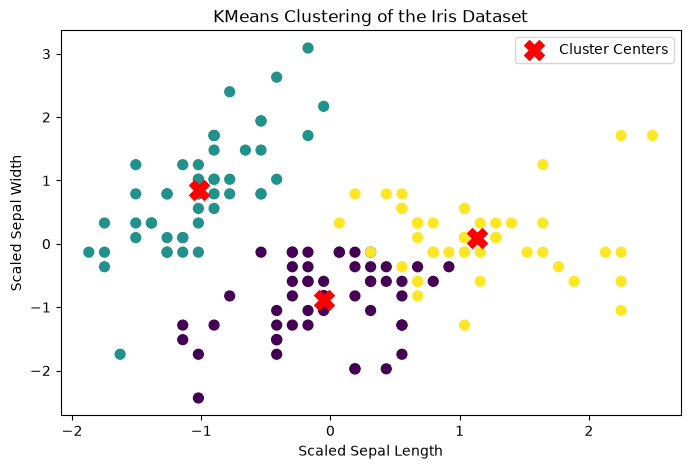

In [13]:
# Visualize KMeans clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    df_scaled["sepal length (cm)"],
    df_scaled["sepal width (cm)"],
    c=kmeans_labels,
    cmap="viridis",
    s=50)
# Display cluster centers
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=200,
    color="red",
    label="Cluster Centers")
plt.xlabel("Scaled Sepal Length")
plt.ylabel("Scaled Sepal Width")
plt.title("KMeans Clustering of the Iris Dataset")
plt.legend()
plt.show()


# Hierarchical Clustering

Hierarchical clustering is an unsupervised machine learning algorithm that groups similar data points into a hierarchy of clusters. Agglomerative hierarchical clustering starts with each data point as its own cluster and repeatedly merges the closest clusters until the desired number of clusters is reached.

Hierarchical clustering is suitable for the Iris dataset because it helps identify groups of flowers with similar measurements. It also provides a way to explore relationships between data points without using the known species labels.

In [14]:
# Hierarchical Clustering
from sklearn.cluster import AgglomerativeClustering
# Create and train the model using scaled data
hierarchical = AgglomerativeClustering(n_clusters=3)
hierarchical_labels = hierarchical.fit_predict(df_scaled)
# Display cluster assignments
print("Hierarchical cluster assignments:")
print(hierarchical_labels)

Hierarchical cluster assignments:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


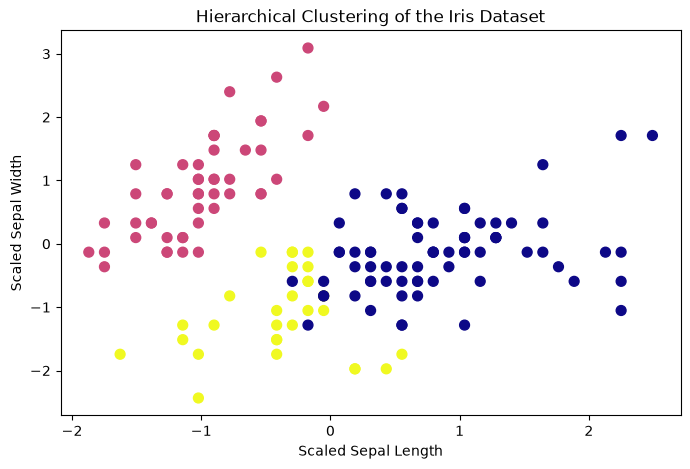

In [15]:
# Visualize Hierarchical clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    df_scaled["sepal length (cm)"],
    df_scaled["sepal width (cm)"],
    c=hierarchical_labels,
    cmap="plasma",
    s=50)
plt.xlabel("Scaled Sepal Length")
plt.ylabel("Scaled Sepal Width")
plt.title("Hierarchical Clustering of the Iris Dataset")
plt.show()

# Interpretation
KMeans and Hierarchical Clustering were applied to the Iris dataset using the four numerical flower measurements, without using the species labels.
KMeans groups data points around cluster centers and repeatedly updates these centers to improve the clusters. Hierarchical Clustering groups data points by repeatedly merging the closest clusters.
Both algorithms identified three clusters in the dataset. KMeans is useful for efficiently grouping similar data points, while Hierarchical Clustering helps explore relationships between data points. The visualizations show how the algorithms group flowers according to their sepal measurements. The clusters may overlap because some Iris species have similar features.